# 04 · Reorder behaviour: what do customers buy again?

**Business question:** which products and departments are bought again and again? For a grocer that buys stock based on known orders, like Picnic, repeat products are the most predictable demand: buying the right quantity of them reduces waste, especially for fresh food.

**Tables used:** `order_products_prior` → `products` → `aisles` / `departments` (first multi-table JOINs of the project).

**Data note:** `reordered = 1` if the user had already bought that product in a previous order. In a user's **first order** every product is new by definition (`reordered = 0`), so first orders are excluded when computing reorder rates.

In [1]:
import duckdb
import pandas as pd
import matplotlib.pyplot as plt

con = duckdb.connect("../data/instacart.duckdb", read_only=True)

def q(sql):
    """Run a SQL query and return a pandas DataFrame."""
    return con.sql(sql).df()

## 4.1 Overall reorder rate
What share of products in an order are reorders? Compute it twice:
1. on all rows of `order_products_prior`
2. excluding each user's first order (JOIN with `orders`, keep `order_number > 1`)

Why are the two numbers different?

In [2]:
q("""
SELECT ROUND(AVG(reordered) * 100, 1) AS reorder_rate
FROM order_products_prior
""")

,reorder_rate
0,59.0


In [5]:
q("""
SELECT ROUND(AVG(op.reordered) * 100, 1) AS reorder_rate
FROM order_products_prior op
JOIN orders o ON op.order_id = o.order_id
WHERE o.order_number > 1
""")

,reorder_rate
0,63.0


Overall reorder rate: 59% on all orders, 63% excluding first orders (where every product is new by definition, so reordered is always 0). From the second order on, almost 2 products out of 3 are repeat purchases.

## 4.2 Reorder rate by department
For each department: number of items sold, share of all items (%) and reorder rate (%). Exclude first orders. Save the result as `dept` with columns `department`, `n_items`, `pct_items`, `reorder_rate`.

In [9]:
dept = q("""
SELECT d.department,
       COUNT(*) AS n_items,
       ROUND(COUNT(*) * 100.0 / SUM(COUNT(*)) OVER (), 1) AS pct_items,
       ROUND(AVG(op.reordered) * 100, 1)                  AS reorder_rate
FROM order_products_prior op
JOIN orders o      ON op.order_id = o.order_id
JOIN products p    ON op.product_id = p.product_id
JOIN departments d ON p.department_id = d.department_id
WHERE o.order_number > 1
GROUP BY d.department
ORDER BY reorder_rate DESC
""")
dept

,department,n_items,pct_items,reorder_rate
0,dairy eggs,5080986,16.7,71.4
1,beverages,2522511,8.3,69.7
2,produce,8894907,29.3,69.3
3,bakery,1101246,3.6,67.1
4,deli,981150,3.2,65.1
5,pets,91101,0.3,64.5
6,alcohol,140982,0.5,62.1
7,snacks,2706641,8.9,61.3
8,babies,401315,1.3,61.1
9,bulk,32812,0.1,60.8


Fresh departments lead the reorder ranking: dairy & eggs 71.4%, produce 69.3%, bakery 67.1%, deli 65.1%. Produce is also the largest department (29.3% of items). Pantry, personal care and household are reordered least (34–43%): long-lasting goods bought occasionally. Fresh food spoils fastest but is also the most predictable demand: ideal for a pre-order model to buy exactly what is needed and reduce waste.

### Chart: reorder rate by department

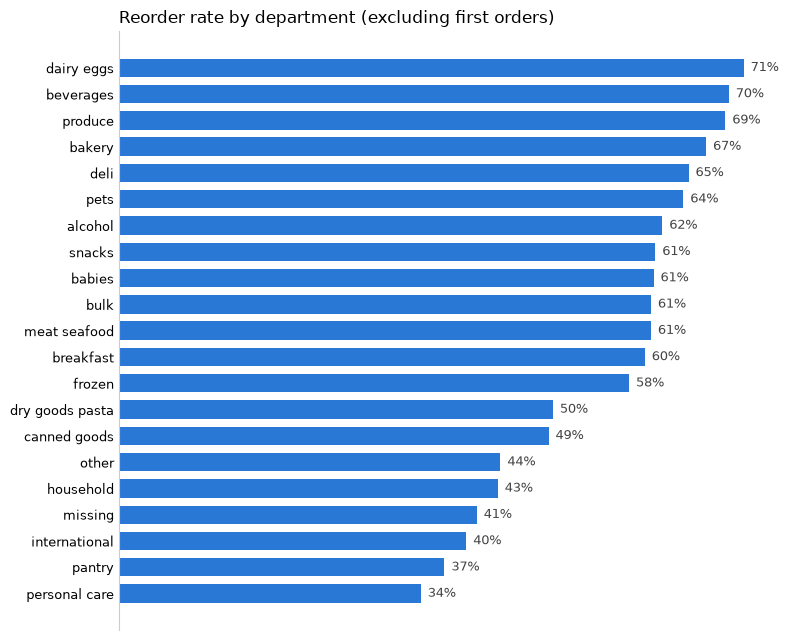

In [10]:
d = dept.sort_values("reorder_rate")
fig, ax = plt.subplots(figsize=(8, 6.5))
ax.barh(d["department"], d["reorder_rate"], color="#2a78d6", height=0.7)
for i, v in enumerate(d["reorder_rate"]):
    ax.text(v + 0.8, i, f"{v:.0f}%", va="center", fontsize=9, color="#444")
ax.xaxis.set_visible(False)
for side in ["top", "right", "bottom"]:
    ax.spines[side].set_visible(False)
ax.spines["left"].set_color("#ccc")
ax.tick_params(axis="y", labelsize=9, length=0)
ax.set_title("Reorder rate by department (excluding first orders)", loc="left", fontsize=12)
plt.tight_layout()
plt.savefig("../figures/reorder_by_department.png", dpi=150, bbox_inches="tight")
plt.show()

## 4.3 Top 20 products
The 20 most ordered products, with how many times they were ordered and their reorder rate. What do they have in common?

In [14]:
q("""
SELECT p.product_name,
        COUNT(*) AS n_orders,
        ROUND(AVG(op.reordered) * 100, 1) AS reorder_rate
FROM order_products_prior op
JOIN orders o ON op.order_id = o.order_id
JOIN products p ON op.product_id = p.product_id
WHERE o.order_number > 1
GROUP BY p.product_id, p.product_name
ORDER BY n_orders DESC
LIMIT 20
""")

,product_name,n_orders,reorder_rate
0,Banana,443031,90.0
1,Bag of Organic Bananas,360292,87.7
2,Organic Strawberries,248219,82.9
3,Organic Baby Spinach,226973,82.3
4,Organic Hass Avocado,202478,84.0
5,Organic Avocado,161628,82.9
6,Large Lemon,144297,73.6
7,Strawberries,134291,74.3
8,Limes,132029,72.5
9,Organic Whole Milk,130682,87.6


The 20 most ordered products are all fresh: 19 are fruit & vegetables, 1 is milk; 15 are organic. All are reordered 68–90% of the time (vs 63% overall). Bananas alone account for 800k+ purchases with ~90% reorder rate. The most perishable products are also the most predictable ones.

## 4.4 Fresh vs packaged
Group departments into **Fresh** (`produce`, `dairy eggs`, `meat seafood`, `bakery`, `deli`) and **Other**. For each group: share of items (%) and reorder rate (%).

In [16]:
q("""
SELECT
    CASE
        WHEN d.department IN ('meat seafood', 'bakery', 'dairy eggs', 'deli', 'produce') THEN 'Fresh'
        ELSE 'Other'
    END AS category,
    COUNT(*)                                           AS n_items,
    ROUND(COUNT(*) * 100.0 / SUM(COUNT(*)) OVER (), 1) AS pct_items,
    ROUND(AVG(op.reordered) * 100, 1)                  AS reorder_rate
FROM order_products_prior op
JOIN orders o      ON op.order_id = o.order_id
JOIN products p    ON op.product_id = p.product_id
JOIN departments d ON p.department_id = d.department_id
WHERE o.order_number > 1
GROUP BY category
""")

,category,n_items,pct_items,reorder_rate
0,Other,13636568,44.9,55.4
1,Fresh,16719853,55.1,69.2


Fresh departments (produce, dairy & eggs, meat & seafood, bakery, deli) account for 55% of all items and are reordered much more often than other products (69.2% vs 55.4%). The biggest and most perishable part of the basket is also the most predictable.

## 4.5 Do reorders go into the cart first?
Compare the average `add_to_cart_order` (position in the cart) for reordered vs new products.

In [18]:
q("""
SELECT op.reordered,
       COUNT(*)                                AS n_items,
       ROUND(AVG(op.add_to_cart_order), 1)     AS avg_cart_position
FROM order_products_prior op
JOIN orders o ON op.order_id = o.order_id
WHERE o.order_number > 1
GROUP BY reordered
ORDER BY op.reordered
""")

,reordered,n_items,avg_cart_position
0,0,11229885,9.7
1,1,19126536,7.6


## Findings & recommendation

**1. Most of the basket is repeat purchases.**
From the second order on, 63% of products are items the customer had already bought (59% if first orders are included, where every product is new by definition).

**2. Fresh food is the biggest and the most predictable part of the basket.**
Fresh departments (produce, dairy & eggs, meat & seafood, bakery, deli) are 55% of all items and are reordered much more often than other products (69.2% vs 55.4%). Dairy & eggs (71.4%) and produce (69.3%, also the largest department with 29% of items) lead the ranking; pantry, household and personal care are reordered least (34–43%).

**3. The top sellers are all fresh, and customers add them first.**
The 20 most ordered products are all fresh (19 fruit & vegetables, 1 milk; 15 organic) with reorder rates of 68–90%; bananas alone account for 800k+ purchases. Reordered products are added to the cart earlier than new ones (average position 7.6 vs 9.7).

**Recommendation**
For a pre-order grocer like Picnic, the most perishable products are also the most predictable: buying fresh stock from known repeat demand can cut waste where it costs most. In the app, a "Buy again" section at the top of the shopping flow would match how customers already shop (repeat items first) and make the weekly order faster.

**Caveats:** no prices (items ≠ revenue); department labels are Instacart's ("missing" and "other" are <0.5% of items); the cart-position gap may be partly driven by basket size.